In [1]:
!pip install langchain langchain_core langgraph -qqq

### **Iterative Workflow undestanding using tweet generator and evaluator**

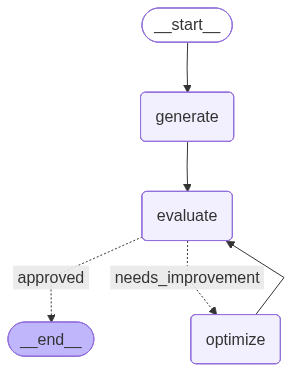

In [2]:
!pip install langchain_openai -qqq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.8/84.8 kB 2.9 MB/s eta 0:00:00


In [7]:
from langgraph.graph import StateGraph,START,END
from pydantic import BaseModel,Field
from typing import TypedDict,Annotated,Literal
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage,SystemMessage

In [5]:
import os
from google.colab import userdata
os.environ['OPENAI_API_KEY']=userdata.get('OPENAI_API_KEY')

In [6]:
llm=ChatOpenAI(model='gpt-5-nano')

In [35]:
class structured_output_for_evaluator(BaseModel):
  evaluation: Literal["approved","needs_improvement"]=Field(description="Final evaluation result for a tweiiter tweet")
  feedback:str =Field(description="contructive feedback for tweet")

In [36]:
structured_llm=llm.with_structured_output(structured_output_for_evaluator)

In [37]:
structured_llm.invoke("Quality is owe ...")

structured_output_for_evaluator(evaluation='needs_improvement', feedback='The input is incomplete and unclear as a standalone tweet. If you intended a slogan or a tweet, consider completing the phrase with a clear subject and verb. Also decide on tone (bold, professional, edgy) and audience. Here are a few polished options and notes on grammar.\n\nSuggestions (short, tweet-ready):\n- Quality is owed to our customers. No shortcuts.\n- Quality is owed. Always.\n- Quality is owed—and we deliver.\n- Quality is owed, not promised.\n- Quality is owed. That’s our standard.\n\nGrammar note: The phrase should be "Quality is owed" (not "Quality is owe"). If you want to express a duty to someone, you can say "Quality is owed to our customers" or "Quality is owed to you." If you share the intended audience or brand voice, I can tailor options further.')

In [60]:
import operator
# state
class TweetState(TypedDict):

    topic: str
    tweet: str
    evaluation: Literal["approved", "needs_improvement"]
    feedback: str
    iteration: int
    max_iteration: int

    tweet_history: Annotated[list[str], operator.add]
    feedback_history: Annotated[list[str], operator.add]

In [62]:
def generate_tweet(state: TweetState):

    # prompt
    messages = [
        SystemMessage(content="You are a funny and clever Twitter/X influencer."),
        HumanMessage(content=f"""
Write a short, original, and hilarious tweet on the topic: "{state['topic']}".

Rules:
- Do NOT use question-answer format.
- Max 280 characters.
- Use observational humor, irony, sarcasm, or cultural references.
- Think in meme logic, punchlines, or relatable takes.
- Use simple, day to day english
""")
    ]

    # send generator_llm
    response = llm.invoke(messages).content

    # return response
    return {'tweet': response, 'tweet_history': [response]}

In [65]:
def evaluate_tweet(state: TweetState):

    # prompt
    messages = [
    SystemMessage(content="You are a ruthless, no-laugh-given Twitter critic. You evaluate tweets based on humor, originality, virality, and tweet format."),
    HumanMessage(content=f"""
Evaluate the following tweet:

Tweet: "{state['tweet']}"

Use the criteria below to evaluate the tweet:

1. Originality – Is this fresh, or have you seen it a hundred times before?
2. Humor – Did it genuinely make you smile, laugh, or chuckle?
3. Punchiness – Is it short, sharp, and scroll-stopping?
4. Virality Potential – Would people retweet or share it?
5. Format – Is it a well-formed tweet (not a setup-punchline joke, not a Q&A joke, and under 280 characters)?

Auto-reject if:
- It's written in question-answer format (e.g., "Why did..." or "What happens when...")
- It exceeds 280 characters
- It reads like a traditional setup-punchline joke
- Dont end with generic, throwaway, or deflating lines that weaken the humor (e.g., “Masterpieces of the auntie-uncle universe” or vague summaries)

### Respond ONLY in structured format:
- evaluation: "approved" or "needs_improvement"
- feedback: One paragraph explaining the strengths and weaknesses
""")
]

    response = structured_llm.invoke(messages)

    return {'evaluation':response.evaluation, 'feedback': response.feedback, 'feedback_history': [response.feedback]}

In [67]:
def optimize_tweet(state: TweetState):

    messages = [
        SystemMessage(content="You punch up tweets for virality and humor based on given feedback."),
        HumanMessage(content=f"""
Improve the tweet based on this feedback:
"{state['feedback']}"

Topic: "{state['topic']}"
Original Tweet:
{state['tweet']}

Re-write it as a short, viral-worthy tweet. Avoid Q&A style and stay under 280 characters.
""")
    ]

    response = optimizer_llm.invoke(messages).content
    iteration = state['iteration'] + 1

    return {'tweet': response, 'iteration': iteration, 'tweet_history': [response]}

In [68]:
def route_evaluation(state: TweetState):

    if state['evaluation'] == 'approved' or state['iteration'] >= state['max_iteration']:
        return 'approved'
    else:
        return 'needs_improvement'

In [69]:
#make graph
graph=StateGraph(TweetState)

#add nodes
graph.add_node("generate",generate_tweet)
graph.add_node("evaluate",evaluate_tweet)
graph.add_node("optimize",optimize_tweet)

#add edges
graph.add_edge(START,'generate')
graph.add_edge("generate","evaluate")

graph.add_conditional_edges('evaluate', route_evaluation, {'approved': END, 'needs_improvement': 'optimize'})

graph.add_edge('optimize', 'evaluate')

#compile graph
workflow=graph.compile()

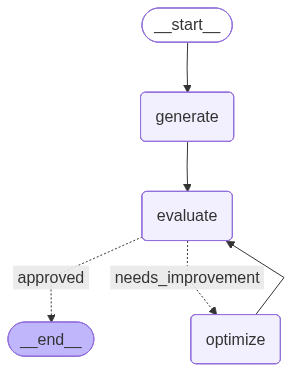

In [26]:
workflow

In [70]:
initial_state = {
    "topic": "srhberhb",
    "iteration": 1,
    "max_iteration": 5
}
result = workflow.invoke(initial_state)

In [71]:
result

{'topic': 'srhberhb',
 'tweet': '"srhberhb" is the password my brain cooks up at 2am: bold, chaotic, and somehow convinced it’s secure. It auto-corrects to existential dread and a reminder that I should write things down instead of vibing my way through life.',
 'evaluation': 'approved',
 'feedback': "Originality: the 'srhberhb' password premise is quirky and distinctive, giving the tweet a memorable hook. The 2am brain and auto-correct to existential dread add relatable humor and a modern vibe with “vibing” language. Humor and format: it reads as a single, non-Q&A, non-setup-punchline line and stays within 280 characters, which helps its scroll-stopping potential. Virality potential is solid due to the unique password twist and relatable anxiety. Areas to sharpen: the joke could punch up a touch more with a tighter two-sentence structure or a slightly sharper ending to avoid any sense of a soft takeaway. Also, the opening quotes around the password look odd in some feeds—clean typogra

In [72]:
for tweet in result['tweet_history']:
    print(tweet)

"srhberhb" is the password my brain cooks up at 2am: bold, chaotic, and somehow convinced it’s secure. It auto-corrects to existential dread and a reminder that I should write things down instead of vibing my way through life.
